In [1]:
# Import modules
import os
import sys

# Make sure that the executable path exists in the environment path
env_bin = os.path.dirname(sys.executable)
if env_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{env_bin}:{os.environ['PATH']}"

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cm
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import scipy.signal as signal
import xarray as xr
import yaml

with open("config.yml") as f:
    config = yaml.safe_load(f)
viz_opts = config["viz"]

In [2]:
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=4, threads_per_worker=4)
client = Client(cluster)
client

/albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 45213 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:45213/status,
Dashboard: http://127.0.0.1:45213/status,Workers: 4
Total threads: 16,Total memory: 64.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40153,Workers: 0
Dashboard: http://127.0.0.1:45213/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:35395,Total threads: 4
Dashboard: http://127.0.0.1:43393/status,Memory: 16.00 GiB
Nanny: tcp://127.0.0.1:34349,


2026-10-16 18:15:03,222 - tornado.application - ERROR - Uncaught exception GET /status/ws (127.0.0.1)
HTTPServerRequest(protocol='http', host='jupyterhub.awi.de', method='GET', uri='/status/ws', version='HTTP/1.1', remote_ip='127.0.0.1')
Traceback (most recent call last):
  File "/albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/lib/python3.12/site-packages/tornado/websocket.py", line 965, in _accept_connection
    open_result = handler.open(*handler.open_args, **handler.open_kwargs)
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/lib/python3.12/site-packages/tornado/web.py", line 3409, in wrapper
    return method(self, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/lib/python3.12/site-packages/bokeh/server/views/ws.py", line 149, in open
    raise ProtocolError("Token is expired. Configure the app with a larger v

In [3]:
def setup_Weddell_Sea(fig):

    # Define the projection for a high-resolution South Polar Stereographic map
    high_res_proj = ccrs.SouthPolarStereo(central_longitude=-50)
    high_res_proj.threshold = 1e3

    ax = fig.add_subplot(111, projection=high_res_proj)
    ax.add_feature(cfeature.LAND, color="grey")

    # Define the limits for the x-axis and y-axis of the map
    xlim = [-80, -20]  # longitude
    ylim = [-50, -80]  # latitude

    # Define a rectangular path for the map extent using matplotlib's Path object
    rect = mpath.Path(
        [
            [xlim[0], ylim[0]],
            [xlim[1], ylim[0]],
            [xlim[1], ylim[1]],
            [xlim[0], ylim[1]],
            [xlim[0], ylim[0]],
        ]
    )

    # Transform the rectangular path to the data coordinate system
    proj_to_data = ccrs.PlateCarree()._as_mpl_transform(ax) - ax.transData
    rect_in_target = proj_to_data.transform_path(rect)

    # Set the boundary of the map using the transformed rectangular path
    ax.set_boundary(rect_in_target)

    # Configure gridlines for the map
    gl = ax.gridlines(draw_labels=["top", "right", "x", "y"], rotate_labels=True, x_inline=False)

    # Draw latitude and longitude gridlines (and their labels)
    # only at the specified values
    lathelp = np.arange(-75, -60, 5)
    gl.ylocator = mticker.FixedLocator(lathelp)
    lonhelp = np.arange(-80, -10, 10)
    gl.xlocator = mticker.FixedLocator(lonhelp)

    # Rotate the longitude labels to be more readable
    gl.xlabel_style = {"rotation": 30}

    # To make sure that all of the wanted map extent is visible in the figure,
    # (especially because the chosen map projections differs strongly
    # at the poles from the PlateCarree Projection)
    # this hack of adding a constant is needed and may need be adjusted,
    # dependent on your map extent and figure size
    ax.set_extent([xlim[0], xlim[1], ylim[0] + 4, ylim[1]])

    return ax

# Load ERA5 Data

In [4]:
# wind = xr.open_dataset("./data/era5_winddata.grib", engine="cfgrib", chunks='auto')
wind = xr.open_dataset(
    "./data/era5_winddata.grib",
    engine="cfgrib",
    chunks={"time": -1, "latitude": 20, "longitude": 20},
)

In [5]:
wind

<xarray.Dataset> Size: 4GB
Dimensions:        (time: 13140, latitude: 161, longitude: 221)
Coordinates:
  * time           (time) datetime64[ns] 105kB 2017-01-01 ... 2019-12-31T22:0...
    valid_time     (time) datetime64[ns] 105kB dask.array<chunksize=(13140,), meta=np.ndarray>
  * latitude       (latitude) float64 1kB -50.0 -50.25 -50.5 ... -89.75 -90.0
  * longitude      (longitude) float64 2kB -75.0 -74.75 -74.5 ... -20.25 -20.0
    number         int64 8B ...
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
Data variables:
    u              (time, latitude, longitude) float32 2GB dask.array<chunksize=(13140, 20, 20), meta=np.ndarray>
    v              (time, latitude, longitude) float32 2GB dask.array<chunksize=(13140, 20, 20), meta=np.ndarray>
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-16T17:57 GRIB to CDM+CF via cfgrib-0.9.1...

In [6]:
print(wind)

<xarray.Dataset> Size: 4GB
Dimensions:        (time: 13140, latitude: 161, longitude: 221)
Coordinates:
  * time           (time) datetime64[ns] 105kB 2017-01-01 ... 2019-12-31T22:0...
    valid_time     (time) datetime64[ns] 105kB dask.array<chunksize=(13140,), meta=np.ndarray>
  * latitude       (latitude) float64 1kB -50.0 -50.25 -50.5 ... -89.75 -90.0
  * longitude      (longitude) float64 2kB -75.0 -74.75 -74.5 ... -20.25 -20.0
    number         int64 8B ...
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
Data variables:
    u              (time, latitude, longitude) float32 2GB dask.array<chunksize=(13140, 20, 20), meta=np.ndarray>
    v              (time, latitude, longitude) float32 2GB dask.array<chunksize=(13140, 20, 20), meta=np.ndarray>
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:       

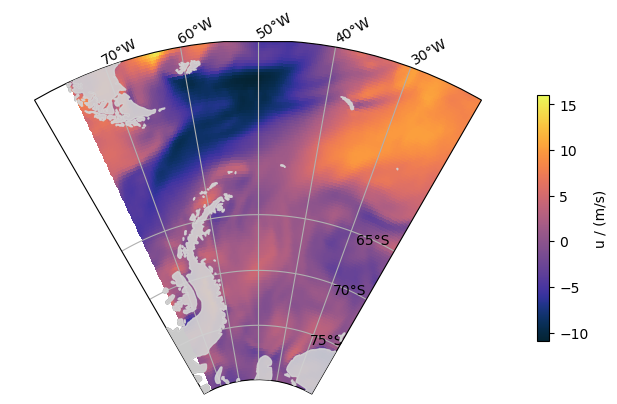

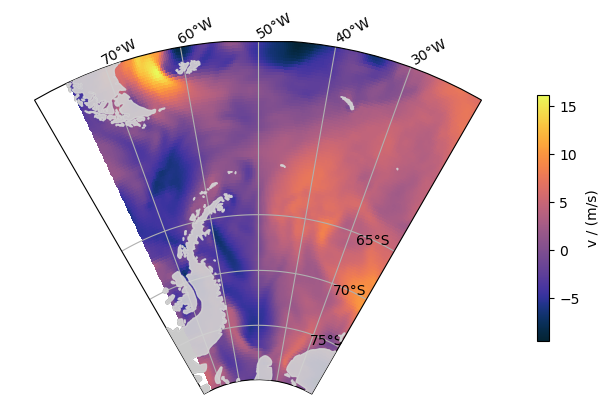

In [7]:
lat = wind.variables["latitude"][:]  # latitude grid points
lon = wind.variables["longitude"][:]  # longitude grid points

fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    lon, lat, wind.isel(time=0).variables["u"], transform=ccrs.PlateCarree(), cmap=cm.cm.thermal
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4, label="u / (m/s)")

fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    lon, lat, wind.isel(time=0).variables["v"], transform=ccrs.PlateCarree(), cmap=cm.cm.thermal
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4, label="v / (m/s)");

In [ ]:
wind = wind.persist()

## filtering

In [8]:
def get_coriolis_frequency(lat, unit="rad/s", absolute=False):

    if absolute:
        lat = abs(lat)

    Omega = 7.2921 * 1e-5  # unit: rad/s

    f = 2 * Omega * np.sin(lat * np.pi / 180.0)

    if unit == "rad/s":
        return f

    if unit == "Hz":
        return f / (2 * np.pi)

    if unit == "cpd":
        return f / (2 * np.pi) * 3600 * 24

    raise NotImplementedError("Specified unit is not implemented")

In [9]:
# lat_field = get_coriolis_frequency(lat=wind.variables['latitude'], unit="Hz", absolute=True)
# lat_field
# lat = lat_field.variables['latitude'][:] # latitude grid points
# lon = lat_field.variables['longitude'][:] # longitude grid points

# fig = plt.figure(figsize=(8, 8))
# ax = setup_Weddell_Sea(fig)
# im= ax.pcolormesh(lon, lat, wind.isel(time=0).variables['u'], transform=ccrs.PlateCarree(), cmap = cm.cm.thermal)
# ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder = 10)
# #ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
# plt.colorbar(im, orientation='vertical', shrink = 0.4, label="u / (m/s)");

# fig = plt.figure(figsize=(8, 8))
# ax = setup_Weddell_Sea(fig)
# im= ax.pcolormesh(lon, lat, wind.isel(time=0).variables['v'], transform=ccrs.PlateCarree(), cmap = cm.cm.thermal)
# ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder = 10)
# #ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
# plt.colorbar(im, orientation='vertical', shrink = 0.4, label="v / (m/s)");

In [10]:
mean_lat = -64
mean_f_in_Hz = get_coriolis_frequency(lat=mean_lat, unit="Hz", absolute=True)

In [11]:
def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    """
    # Sample rate and desired cutoff frequencies (in Hz).
    fs = 1/7200 #sampling period of 2 hours
    lowcut = 1/(14*60*60) #period of 18 hours
    highcut = 1/(10*60*60) #period of 10 hours
    filtered_u = butter_bandpass_filter(patched_u, lowcut, highcut, fs, order=6)
    filtered_v = butter_bandpass_filter(patched_v, lowcut, highcut, fs, order=6)
    """
    # from scipy.signal import lfilter
    # b, a = Data.butter_bandpass(lowcut, highcut, fs, order=order)
    # y = lfilter(b, a, data)

    # use of second-order sections (sos) as recommended in https://docs.scipy.org/doc/scipy-1.14.1/reference/generated/scipy.signal.butter.html
    sos = signal.butter(order, [lowcut, highcut], "bandpass", fs=fs, output="sos")
    # use filtfilt with 2 filtering passes to prevent an artificial phase shift
    filtered = signal.sosfiltfilt(sos, data)

    return filtered

In [12]:
def filter_wind_field_to_f(data):
    lowcut = mean_f_in_Hz * 0.9
    highcut = mean_f_in_Hz * 1.1
    two_hour_period = 1 / 7200
    return butter_bandpass_filter(data, lowcut, highcut, fs=two_hour_period, order=5)

In [13]:
# wind.map(filter_wind_field_to_f)

In [14]:
wind.variables["u"]

<xarray.Variable (time: 13140, latitude: 161, longitude: 221)> Size: 2GB
dask.array<open_dataset-u, shape=(13140, 161, 221), dtype=float32, chunksize=(13140, 20, 20), chunktype=numpy.ndarray>
Attributes: (12/31)
    GRIB_paramId:                             131
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      35581
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:                           u
    GRIB_totalNumber:                         0
    GRIB_units:                               m s**-1
    long_name:                                U component of wind
    units:                                    m s**-1
    standard_name:                            eastward_wind

In [15]:
def apply_filter(da):
    return xr.apply_ufunc(
        filter_wind_field_to_f,
        da,
        input_core_dims=[["time"]],
        output_core_dims=[["time"]],
        dask="parallelized",
        output_dtypes=[da.dtype],
        kwargs={},
    ).transpose("time", "latitude", "longitude")


filtered_u = apply_filter(wind["u"])
filtered_v = apply_filter(wind["v"])

filtered = xr.Dataset({"u": filtered_u, "v": filtered_v})

In [16]:
filtered.to_zarr("inertial_wind_field.zarr", mode="w")

/albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [17]:
# filtered.to_grib("inertial_wind_field.grib")

In [18]:
# inertial_wind_field = filtered.compute()

In [19]:
# filtered_u.compute()

In [20]:
# filtered_v.comp

In [21]:
# inertial_wind_field = filtered.compute()